# Concentración de cartera: por qué el HHI de exposiciones no basta

**Perfil:** Riesgo de crédito (estrategia y portafolio)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

El índice Herfindahl-Hirschman (HHI) mide qué tan repartida está la exposición. ¿Dos carteras con el **mismo** HHI tienen el **mismo** riesgo? Si no, ¿qué medida de concentración sí acompaña al riesgo?

## Recorrido

1. Cartera sintética de 300 deudores en 8 sectores, con un modelo de factores (global + sectorial) que genera pérdidas.
2. **Versión 1:** HHI por deudor y por sector, número efectivo, participación de los mayores.
3. **Diagnóstico:** cuatro carteras con las **mismas exposiciones** pero distinta asignación de sector y PD: el HHI de nombres es idéntico, el riesgo no.
4. **Versión 2:** concentración medida sobre las **contribuciones al riesgo** (expected shortfall, asignación de Euler).
5. Propiedades del índice, ruido de simulación, sensibilidad, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.stats import norm

## 2. Cartera y modelo de pérdidas

300 deudores con exposiciones log-normales (cola pesada: unos pocos grandes), 8 sectores, PD y LGD heterogéneas. Las pérdidas siguen un modelo de factores gaussiano: el rendimiento de activos del deudor $i$ del sector $s$ es

$$A_i=\sqrt{\rho_G}\,G+\sqrt{\rho_S}\,S_{s}+\sqrt{1-\rho_G-\rho_S}\;\varepsilon_i,$$

y el deudor incumple si $A_i<\Phi^{-1}(\mathrm{PD}_i)$. $G$ es un factor **global** y $S_s$ un factor **sectorial**: deudores del mismo sector comparten más riesgo.

In [2]:
N, SECTORES, S_SIM = 300, 8, 60_000
RHO_G, RHO_S = 0.08, 0.14
rng = np.random.default_rng(SEED)

exposicion = np.sort(rng.lognormal(12, 1.1, N))[::-1]             # de mayor a menor
pd_ = rng.beta(2, 60, N) * 1.0 + 0.004                            # PD entre ~0.4% y ~10%
lgd = rng.uniform(0.35, 0.60, N)
sector0 = rng.integers(0, SECTORES, N)

# numeros aleatorios comunes: los mismos G, S, eps para todas las carteras que se comparen
G = rng.standard_normal((S_SIM, 1)).astype(np.float32)
S = rng.standard_normal((S_SIM, SECTORES)).astype(np.float32)
EPS = rng.standard_normal((S_SIM, N)).astype(np.float32)
print(f"exposicion total = {exposicion.sum():,.0f} | mayor deudor = {exposicion[0] / exposicion.sum():.2%} | PD media = {pd_.mean():.3%}")

exposicion total = 107,832,767 | mayor deudor = 4.83% | PD media = 3.441%


In [3]:
def simular_perdidas(exp, sector, pd_i, lgd_i):
    # devuelve la matriz de perdidas por deudor (S_SIM x N); L_ij = LGD*EAD si el deudor j incumple
    umbral = norm.ppf(pd_i).astype(np.float32)
    A = np.sqrt(RHO_G) * G + np.sqrt(RHO_S) * S[:, sector] + np.sqrt(1 - RHO_G - RHO_S) * EPS
    return ((A < umbral) * (lgd_i * exp).astype(np.float32)).astype(np.float32)


def metricas_perdida(L, nivel=0.995):
    total = L.sum(axis=1)
    var = np.quantile(total, nivel)
    cola = total >= var
    es = total[cola].mean()
    # error estandar de VaR y ES por lotes
    lotes = np.array_split(np.arange(len(total)), 10)
    var_l = [np.quantile(total[ix], nivel) for ix in lotes]
    es_l = [total[ix][total[ix] >= np.quantile(total[ix], nivel)].mean() for ix in lotes]
    return {"EL": total.mean(), "VaR": var, "ES": es, "se_VaR": np.std(var_l) / np.sqrt(10), "se_ES": np.std(es_l) / np.sqrt(10), "cola": cola}

L0 = simular_perdidas(exposicion, sector0, pd_, lgd)
m0 = metricas_perdida(L0)
print(f"cartera base: EL={m0['EL']:,.0f} | VaR99.5%={m0['VaR']:,.0f} (+-{m0['se_VaR']:,.0f}) | ES99.5%={m0['ES']:,.0f} (+-{m0['se_ES']:,.0f})")

cartera base: EL=1,690,838 | VaR99.5%=8,264,638 (+-59,793) | ES99.5%=9,757,177 (+-75,796)


## 3. Versión 1: HHI, número efectivo y participaciones

$$\mathrm{HHI}=\sum_i w_i^2,\quad w_i=\frac{\text{exposición}_i}{\sum_j \text{exposición}_j},\qquad N_{\text{ef}}=\frac{1}{\mathrm{HHI}}\in[1,N].$$

In [4]:
def hhi(x):
    w = np.asarray(x, float) / np.sum(x)
    return float((w ** 2).sum())

def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))

def resumen_hhi(exp, sector):
    por_sector = pd.Series(exp).groupby(sector).sum()
    return {"HHI_nombres": hhi(exp), "N_efectivo": 1 / hhi(exp), "HHI_sectores": hhi(por_sector), "sectores_efectivos": 1 / hhi(por_sector),
            "top10_%": np.sort(exp)[::-1][:10].sum() / exp.sum() * 100, "mayor_%": exp.max() / exp.sum() * 100, "Gini": gini(exp)}

pd.Series(resumen_hhi(exposicion, sector0), name="cartera base").to_frame()

,cartera base
HHI_nombres,0.0125
N_efectivo,79.7992
HHI_sectores,0.1370
sectores_efectivos,7.3011
top10_%,27.4726
mayor_%,4.8311
Gini,0.6024


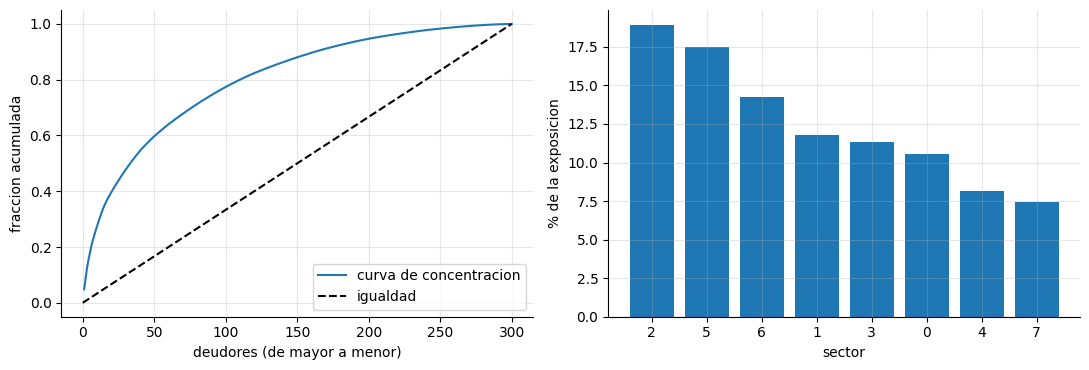

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
w = exposicion / exposicion.sum()
ax[0].plot(np.arange(1, N + 1), np.cumsum(w), label="curva de concentracion"); ax[0].plot([0, N], [0, 1], "k--", label="igualdad")
ax[0].set_xlabel("deudores (de mayor a menor)"); ax[0].set_ylabel("fraccion acumulada"); ax[0].legend()
por_sec = pd.Series(exposicion).groupby(sector0).sum().sort_values(ascending=False)
ax[1].bar(por_sec.index.astype(str), por_sec / por_sec.sum() * 100); ax[1].set_xlabel("sector"); ax[1].set_ylabel("% de la exposicion")
plt.tight_layout(); plt.show()

## 4. Diagnóstico: mismas exposiciones, distinto riesgo

El HHI de nombres depende **solo del vector de exposiciones**. Si se reasignan sector y PD entre los deudores sin tocar ese vector, el HHI de nombres no puede cambiar. Se construyen cuatro carteras con **exactamente las mismas exposiciones**:

| cartera | los 20 mayores deudores... |
|---|---|
| `base` | quedan como en la cartera original |
| `sector_concentrado` | están **todos en el sector 0** |
| `sector_diversificado` | se reparten entre los 8 sectores |
| `PD_alta` / `PD_baja` | tienen las PD más **altas** / más **bajas** |

In [6]:
def reasignar(modo):
    sec, pdi, lg = sector0.copy(), pd_.copy(), lgd.copy()
    top = np.arange(20)
    if modo == "sector_concentrado":
        sec[top] = 0
    elif modo == "sector_diversificado":
        sec[top] = np.arange(20) % SECTORES
    elif modo in ("PD_alta", "PD_baja"):
        orden = np.argsort(pd_)
        orden = orden[::-1] if modo == "PD_alta" else orden
        pdi[top] = pd_[orden[:20]]
        resto = np.setdiff1d(np.arange(N), top)
        pdi[resto] = pd_[orden[20:]]
    return sec, pdi, lg

carteras = {m: reasignar(m) for m in ("base", "sector_concentrado", "sector_diversificado", "PD_alta", "PD_baja")}
filas, perdidas = {}, {}
for nombre, (sec, pdi, lg) in carteras.items():
    L = simular_perdidas(exposicion, sec, pdi, lg); perdidas[nombre] = L
    m = metricas_perdida(L)
    filas[nombre] = {**resumen_hhi(exposicion, sec), "EL": m["EL"], "VaR": m["VaR"], "ES": m["ES"], "se_ES": m["se_ES"]}
diag = pd.DataFrame(filas).T
diag[["HHI_nombres", "HHI_sectores", "sectores_efectivos", "EL", "VaR", "ES", "se_ES"]].round(4)

,HHI_nombres,HHI_sectores,sectores_efectivos,EL,VaR,ES,se_ES
base,0.0125,0.1370,7.3011,"1,690,838.2500","8,264,638.5000","9,757,177.0000","75,796.2528"
sector_concentrado,0.0125,0.2490,4.0169,"1,694,670.2500","9,037,839.0000","10,849,756.0000","152,298.9287"
sector_diversificado,0.0125,0.1265,7.9033,"1,696,578.3750","8,291,607.5000","9,728,725.0000","98,188.2272"
PD_alta,0.0125,0.1370,7.3011,"3,249,715.0000","13,126,759.0000","14,975,923.0000","136,229.3306"
PD_baja,0.0125,0.1370,7.3011,"841,832.3125","4,999,291.5000","6,044,064.0000","93,822.6535"


In [7]:
print("Lectura:")
print(f"  HHI de nombres: identico en las cinco carteras = {diag['HHI_nombres'].nunique() == 1} (valor {diag['HHI_nombres'].iloc[0]:.5f}).")
print(f"  Sin embargo el ES al 99.5% va de {diag['ES'].min():,.0f} ({diag['ES'].idxmin()}) a {diag['ES'].max():,.0f} ({diag['ES'].idxmax()}): un factor de {diag['ES'].max() / diag['ES'].min():.2f}.")
a, b = diag.loc["sector_concentrado"], diag.loc["sector_diversificado"]
z_sec = (a["ES"] - b["ES"]) / np.hypot(a["se_ES"], b["se_ES"])
print(f"  Concentrar los 20 mayores en un sector aumenta el ES en {a['ES'] / b['ES'] - 1:+.1%} respecto de diversificarlos ({z_sec:.1f} errores estandar).")
print(f"  PD alta vs baja entre los mayores: ES {diag.loc['PD_alta', 'ES'] / diag.loc['PD_baja', 'ES']:.2f}x.")
print("  El HHI de sectores SI distingue la concentracion sectorial, pero no ve las diferencias de PD.")

Lectura:
  HHI de nombres: identico en las cinco carteras = True (valor 0.01253).
  Sin embargo el ES al 99.5% va de 6,044,064 (PD_baja) a 14,975,923 (PD_alta): un factor de 2.48.
  Concentrar los 20 mayores en un sector aumenta el ES en +11.5% respecto de diversificarlos (6.2 errores estandar).
  PD alta vs baja entre los mayores: ES 2.48x.
  El HHI de sectores SI distingue la concentracion sectorial, pero no ve las diferencias de PD.


**Qué muestra.** El HHI de exposiciones ignora **quién** es el deudor (su PD y LGD) y **con quién se correlaciona**. El HHI sectorial recoge una parte (la correlación) pero no la calidad crediticia. Ninguno de los dos mide el riesgo directamente.

## 5. Versión 2: concentración sobre las contribuciones al riesgo

Si lo que importa es la **pérdida de cola**, la concentración relevante es la de las **contribuciones al riesgo**. Con la asignación de Euler para el *expected shortfall*:

$$\mathrm{ES}=\sum_i \mathrm{ES}_i,\qquad \mathrm{ES}_i=\mathbb{E}\big[L_i\mid L\ge \mathrm{VaR}\big].$$

Sobre esas contribuciones se calcula un HHI de riesgo y un número efectivo de **fuentes de riesgo**.

In [8]:
def contribuciones_es(L, nivel=0.995):
    total = L.sum(axis=1)
    cola = total >= np.quantile(total, nivel)
    return L[cola].mean(axis=0)

filas = {}
for nombre, L in perdidas.items():
    c = contribuciones_es(L)
    filas[nombre] = {"ES_total": L.sum(axis=1)[L.sum(axis=1) >= np.quantile(L.sum(axis=1), 0.995)].mean(), "suma_contribuciones": c.sum(),
                     "HHI_exposicion": hhi(exposicion), "HHI_riesgo": hhi(c), "N_ef_riesgo": 1 / hhi(c), "top10_riesgo_%": np.sort(c)[::-1][:10].sum() / c.sum() * 100}
riesgo_conc = pd.DataFrame(filas).T
riesgo_conc.round(4)

,ES_total,suma_contribuciones,HHI_exposicion,HHI_riesgo,N_ef_riesgo,top10_riesgo_%
base,"9,757,177.0000","9,757,178.0000",0.0125,0.0348,28.7118,44.6520
sector_concentrado,"10,849,756.0000","10,849,754.0000",0.0125,0.0400,25.0120,49.5818
sector_diversificado,"9,728,725.0000","9,728,726.0000",0.0125,0.0352,28.4251,44.4397
PD_alta,"14,975,923.0000","14,975,924.0000",0.0125,0.0403,24.8249,50.4254
PD_baja,"6,044,064.0000","6,044,064.5000",0.0125,0.0230,43.4969,35.0558


In [9]:
print("Lectura:")
print(f"  La asignacion de Euler es aditiva: suma de contribuciones = ES total en todas las carteras: {np.allclose(riesgo_conc['ES_total'], riesgo_conc['suma_contribuciones'])}")
print(f"  HHI de riesgo va de {riesgo_conc['HHI_riesgo'].min():.4f} ({riesgo_conc['HHI_riesgo'].idxmin()}) a {riesgo_conc['HHI_riesgo'].max():.4f} ({riesgo_conc['HHI_riesgo'].idxmax()}), mientras el HHI de exposicion es siempre {riesgo_conc['HHI_exposicion'].iloc[0]:.4f}.")
print(f"  Correlacion de rangos (5 carteras) entre HHI de riesgo y ES: {pd.Series(riesgo_conc['HHI_riesgo']).rank().corr(pd.Series(riesgo_conc['ES_total']).rank()):+.2f}")
orden_es = riesgo_conc["ES_total"].sort_values().index.tolist()
orden_hhir = riesgo_conc["HHI_riesgo"].sort_values().index.tolist()
print(f"  Orden por ES (menor a mayor):        {orden_es}")
print(f"  Orden por HHI de riesgo (menor a mayor): {orden_hhir}")
z_bd = (diag.loc["base", "ES"] - diag.loc["sector_diversificado", "ES"]) / np.hypot(diag.loc["base", "se_ES"], diag.loc["sector_diversificado", "se_ES"])
print(f"  Los ordenes difieren en 'base' vs 'sector_diversificado', pero su ES se distingue en solo {abs(z_bd):.1f} errores estandar: {'ese intercambio es ruido de simulacion' if abs(z_bd) < 2 else 'esa diferencia es real'}.")

Lectura:
  La asignacion de Euler es aditiva: suma de contribuciones = ES total en todas las carteras: True
  HHI de riesgo va de 0.0230 (PD_baja) a 0.0403 (PD_alta), mientras el HHI de exposicion es siempre 0.0125.
  Correlacion de rangos (5 carteras) entre HHI de riesgo y ES: +0.90
  Orden por ES (menor a mayor):        ['PD_baja', 'sector_diversificado', 'base', 'sector_concentrado', 'PD_alta']
  Orden por HHI de riesgo (menor a mayor): ['PD_baja', 'base', 'sector_diversificado', 'sector_concentrado', 'PD_alta']
  Los ordenes difieren en 'base' vs 'sector_diversificado', pero su ES se distingue en solo 0.2 errores estandar: ese intercambio es ruido de simulacion.


Una cautela: la concentración **de riesgo** también puede **no** coincidir con el nivel de riesgo. Un HHI de riesgo alto significa que **pocos deudores explican la cola**, no que la cola sea grande. Es una medida de *cómo* se reparte el riesgo, útil para decidir dónde actuar; el **nivel** lo da el ES.

### 5.1 ¿Qué deudores explican la cola?

In [10]:
c = contribuciones_es(perdidas["base"])
orden = np.argsort(c)[::-1]
t = pd.DataFrame({"deudor": orden[:10], "exposicion_%": exposicion[orden[:10]] / exposicion.sum() * 100,
                  "contrib_ES_%": c[orden[:10]] / c.sum() * 100, "PD_%": pd_[orden[:10]] * 100, "sector": sector0[orden[:10]]})
t["razon_riesgo/exposicion"] = t["contrib_ES_%"] / t["exposicion_%"]
print("Los 10 deudores que mas contribuyen al ES (cartera base):")
t.round(2)

Los 10 deudores que mas contribuyen al ES (cartera base):


,deudor,exposicion_%,contrib_ES_%,PD_%,sector,razon_riesgo/exposicion
0,0,4.8300,11.2500,2.8600,2,2.3300
1,1,3.9200,8.8500,3.2900,6,2.2600
2,2,3.7400,8.7400,2.0400,5,2.3400
3,8,1.6800,2.9300,4.5800,5,1.7400
4,13,1.4100,2.7700,7.2900,1,1.9600
5,9,1.6700,2.5900,5.0600,5,1.5500
6,3,2.8300,2.0100,1.5800,2,0.7100
7,6,2.0300,1.9800,2.8000,2,0.9800
8,16,1.0800,1.8900,6.1800,5,1.7400
9,20,0.9000,1.6600,9.0600,7,1.8500


In [11]:
rank_exp = pd.Series(exposicion).rank(ascending=False); rank_ries = pd.Series(c).rank(ascending=False)
rho_r = rank_exp.corr(rank_ries, method="spearman")
en_top = len(set(np.argsort(exposicion)[::-1][:10]) & set(orden[:10]))
print(f"Correlacion de rangos entre exposicion y contribucion al ES: {rho_r:+.2f}")
print(f"De los 10 mayores por exposicion, {en_top} estan entre los 10 mayores por contribucion al riesgo.")

Correlacion de rangos entre exposicion y contribucion al ES: +0.91
De los 10 mayores por exposicion, 7 estan entre los 10 mayores por contribucion al riesgo.


## 6. Propiedades del índice y robustez

### 6.1 Cotas, transferencias y fusiones

In [12]:
rg = np.random.default_rng(1)
ok_cotas = ok_transf = ok_split = ok_escala = 0; ensayos = 500
for _ in range(ensayos):
    x = rg.lognormal(0, 1.5, rg.integers(5, 60))
    h = hhi(x); n = len(x)
    ok_cotas += (1 / n - 1e-12 <= h <= 1 + 1e-12)
    # principio de transferencias: pasar exposicion de un deudor menor a uno mayor aumenta el HHI
    i, j = np.argsort(x)[0], np.argsort(x)[-1]
    y = x.copy(); d = 0.5 * y[i]; y[i] -= d; y[j] += d
    ok_transf += hhi(y) > h
    # dividir al mayor en dos mitades reduce el HHI
    z = np.append(np.delete(x, j), [x[j] / 2, x[j] / 2])
    ok_split += hhi(z) < h
    ok_escala += abs(hhi(x * 123.4) - h) < 1e-12
print(f"En {ensayos} carteras aleatorias: cotas {ok_cotas}/{ensayos} | transferencias {ok_transf}/{ensayos} | division del mayor {ok_split}/{ensayos} | invarianza de escala {ok_escala}/{ensayos}")

En 500 carteras aleatorias: cotas 500/500 | transferencias 500/500 | division del mayor 500/500 | invarianza de escala 500/500


### 6.2 Ruido de simulación y de muestreo

In [13]:
# incertidumbre del HHI de nombres por muestreo de deudores (bootstrap)
rb = np.random.default_rng(3)
bs = np.array([hhi(exposicion[rb.integers(0, N, N)]) for _ in range(2000)])
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"HHI de nombres = {hhi(exposicion):.5f}  IC95% bootstrap = [{lo:.5f}, {hi:.5f}]  (ancho relativo {(hi - lo) / hhi(exposicion):.0%})")
# el ES tiene su propio error de simulacion
print(f"ES de la cartera base = {m0['ES']:,.0f} +- {m0['se_ES']:,.0f} ({m0['se_ES'] / m0['ES']:.1%})")

HHI de nombres = 0.01253  IC95% bootstrap = [0.00910, 0.01531]  (ancho relativo 50%)
ES de la cartera base = 9,757,177 +- 75,796 (0.8%)


### 6.3 Sensibilidad a la cola de las exposiciones

In [14]:
filas = []
for sigma in (0.3, 0.7, 1.1, 1.6, 2.2):
    e = np.sort(np.random.default_rng(5).lognormal(12, sigma, N))[::-1]
    filas.append({"sigma": sigma, "HHI": hhi(e), "N_efectivo": 1 / hhi(e), "top10_%": e[:10].sum() / e.sum() * 100, "Gini": gini(e)})
sens = pd.DataFrame(filas).set_index("sigma")
sens.round(4)

,HHI,N_efectivo,top10_%,Gini
sigma,,,,
0.3000,0.0036,275.1539,6.1911,0.1636
0.7000,0.0054,186.4992,12.5685,0.3749
1.1000,0.0101,99.2656,22.2833,0.5604
1.6000,0.0247,40.4495,38.0929,0.7367
2.2000,0.0635,15.7446,58.1072,0.8660


In [15]:
print("Lectura: a mayor dispersion de las exposiciones, el HHI sube y el numero efectivo de deudores cae de", f"{sens['N_efectivo'].iloc[0]:.0f} a {sens['N_efectivo'].iloc[-1]:.0f}", f"(de {N} nominales).")
print("Cota inferior del HHI con N deudores: 1/N =", f"{1 / N:.4f}", "| HHI con sigma minima:", f"{sens['HHI'].iloc[0]:.4f}")

Lectura: a mayor dispersion de las exposiciones, el HHI sube y el numero efectivo de deudores cae de 275 a 16 (de 300 nominales).
Cota inferior del HHI con N deudores: 1/N = 0.0033 | HHI con sigma minima: 0.0036


## 7. Pruebas automáticas

In [16]:
# 7.1 propiedades del HHI en los casos aleatorios
assert ok_cotas == ensayos and ok_transf == ensayos and ok_split == ensayos and ok_escala == ensayos
assert abs(hhi(np.ones(10)) - 0.1) < 1e-12 and abs(hhi([5.0]) - 1.0) < 1e-12
# 7.2 las carteras reasignadas tienen exactamente el mismo HHI de nombres
assert diag["HHI_nombres"].nunique() == 1
# 7.3 el riesgo difiere: concentrar los mayores en un sector aumenta el ES mas alla del ruido de simulacion
assert z_sec > 3, f"efecto sectorial no distinguible del ruido ({z_sec:.1f} se)"
assert diag.loc["PD_alta", "ES"] > diag.loc["PD_baja", "ES"]
assert diag.loc["PD_alta", "EL"] > diag.loc["PD_baja", "EL"]
# 7.4 el HHI sectorial distingue la concentracion sectorial
assert diag.loc["sector_concentrado", "HHI_sectores"] > diag.loc["sector_diversificado", "HHI_sectores"]
# 7.5 la asignacion de Euler es aditiva y las contribuciones son no negativas
assert np.allclose(riesgo_conc["ES_total"], riesgo_conc["suma_contribuciones"], rtol=1e-6)
assert (contribuciones_es(perdidas["base"]) >= 0).all()
# 7.6 el EL de simulacion es coherente con la formula (esperanza del indicador de default)
el_formula = (exposicion * lgd * pd_).sum()
assert abs(m0["EL"] / el_formula - 1) < 0.03, f"EL simulada {m0['EL']:.0f} vs formula {el_formula:.0f}"
# 7.7 la exposicion y la contribucion al riesgo estan relacionadas pero no son lo mismo
assert 0.3 < rho_r < 0.999 and en_top < 10
assert abs(z_bd) < 2, 'base y diversificada no deberian distinguirse del ruido'
# 7.8 el IC bootstrap contiene el valor puntual y el HHI crece con la dispersion
assert lo <= hhi(exposicion) <= hi and sens["HHI"].is_monotonic_increasing
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: HHI de exposición | Mide concentración de nombres con buenas propiedades (cotas, transferencias, escala) | Usarlo como indicador de límite, no como medida de riesgo |
| Diagnóstico | Con las mismas exposiciones, el ES cambia mucho según sector y PD de los mayores deudores | No fiarse de un HHI de nombres para comparar el riesgo de dos carteras |
| HHI sectorial | Distingue la concentración sectorial pero no la calidad crediticia | Combinarlo con medidas que vean PD y LGD |
| v2: contribuciones al ES | La asignación de Euler es aditiva y señala qué deudores explican la cola | Usarla para decidir dónde actuar; el nivel de riesgo lo da el ES |

**Límites que no deben ocultarse**

- El modelo de factores gaussiano (un factor global y uno por sector) es una simplificación; no captura dependencia de cola ni contagio.
- Las contribuciones al ES con 60.000 simulaciones al 99,5 % se apoyan en unas 300 observaciones de cola: son ruidosas a nivel de deudor individual.
- Los parámetros (correlaciones, PD, LGD) son supuestos; con datos reales habría que estimarlos y su incertidumbre afectaría las contribuciones.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.